<center><h1>Tong_Stephanie_HW6</h1></center>

Name: Stephanie Tong
<br>
Github Username: tongstep
<br>
USC ID: 2614015757

## 1. Tree-Based Methods

Import packages

In [1]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, accuracy_score

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from xgboost import XGBClassifier

### (a) Download the APS Failure data

In [3]:
df = pd.read_csv("DSCI552_HW6/data/aps_failure_training_set.csv", skiprows=20, na_values="na")
test_df = pd.read_csv("DSCI552_HW6/data/aps_failure_test_set.csv", skiprows=20, na_values="na")

### (b) Data Preparation

#### (i) Research what types of techniques are usually used

Techniques used for dealing with data with missing values are called data imputation techniques. Methods include:
- Deletion: Removing rows or columns that contain missing values
- Simple Imputation: Replacing missing values with the mean, median, or mode of a feature
- KNN Imputation: Estimating missing values based on values from similar observations
- Multiple Imputation: Creating multiple versions of the dataset with estimated values to account for uncertainty
- Time-Series Imputation: Using methods such as forward-fill, backward-fill, or interpolation to fill in missing values over time

I'm going to use median imputation since median is less sensitive to outliers and this dataset has features that may have extreme values.

#### (ii) Calculate the coefficient of variation

In [4]:
features = df.drop(columns="class")
cv = features.std()/features.mean()
cv

aa_000      2.450938
ab_000      4.878040
ac_000      2.232705
ad_000    211.962417
ae_000     23.689732
             ...    
ee_007      4.990467
ee_008      3.240179
ee_009      5.658710
ef_000     48.232568
eg_000     41.506043
Length: 170, dtype: float64

#### (iii) Plot a correlation matrix

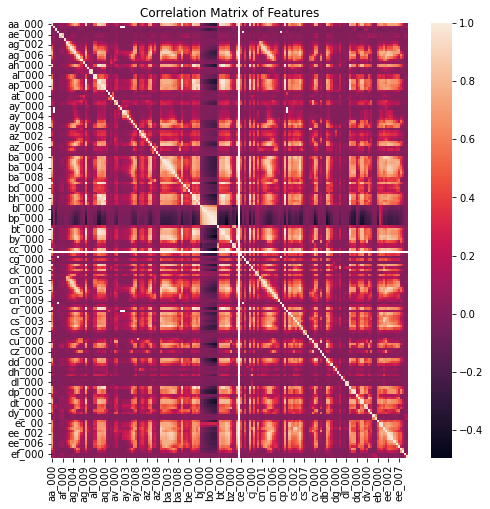

In [5]:
plt.figure(figsize=(8,8))
sns.heatmap(features.corr())
plt.title("Correlation Matrix of Features")
plt.show()

#### (iv) Make scatter plots and box plots

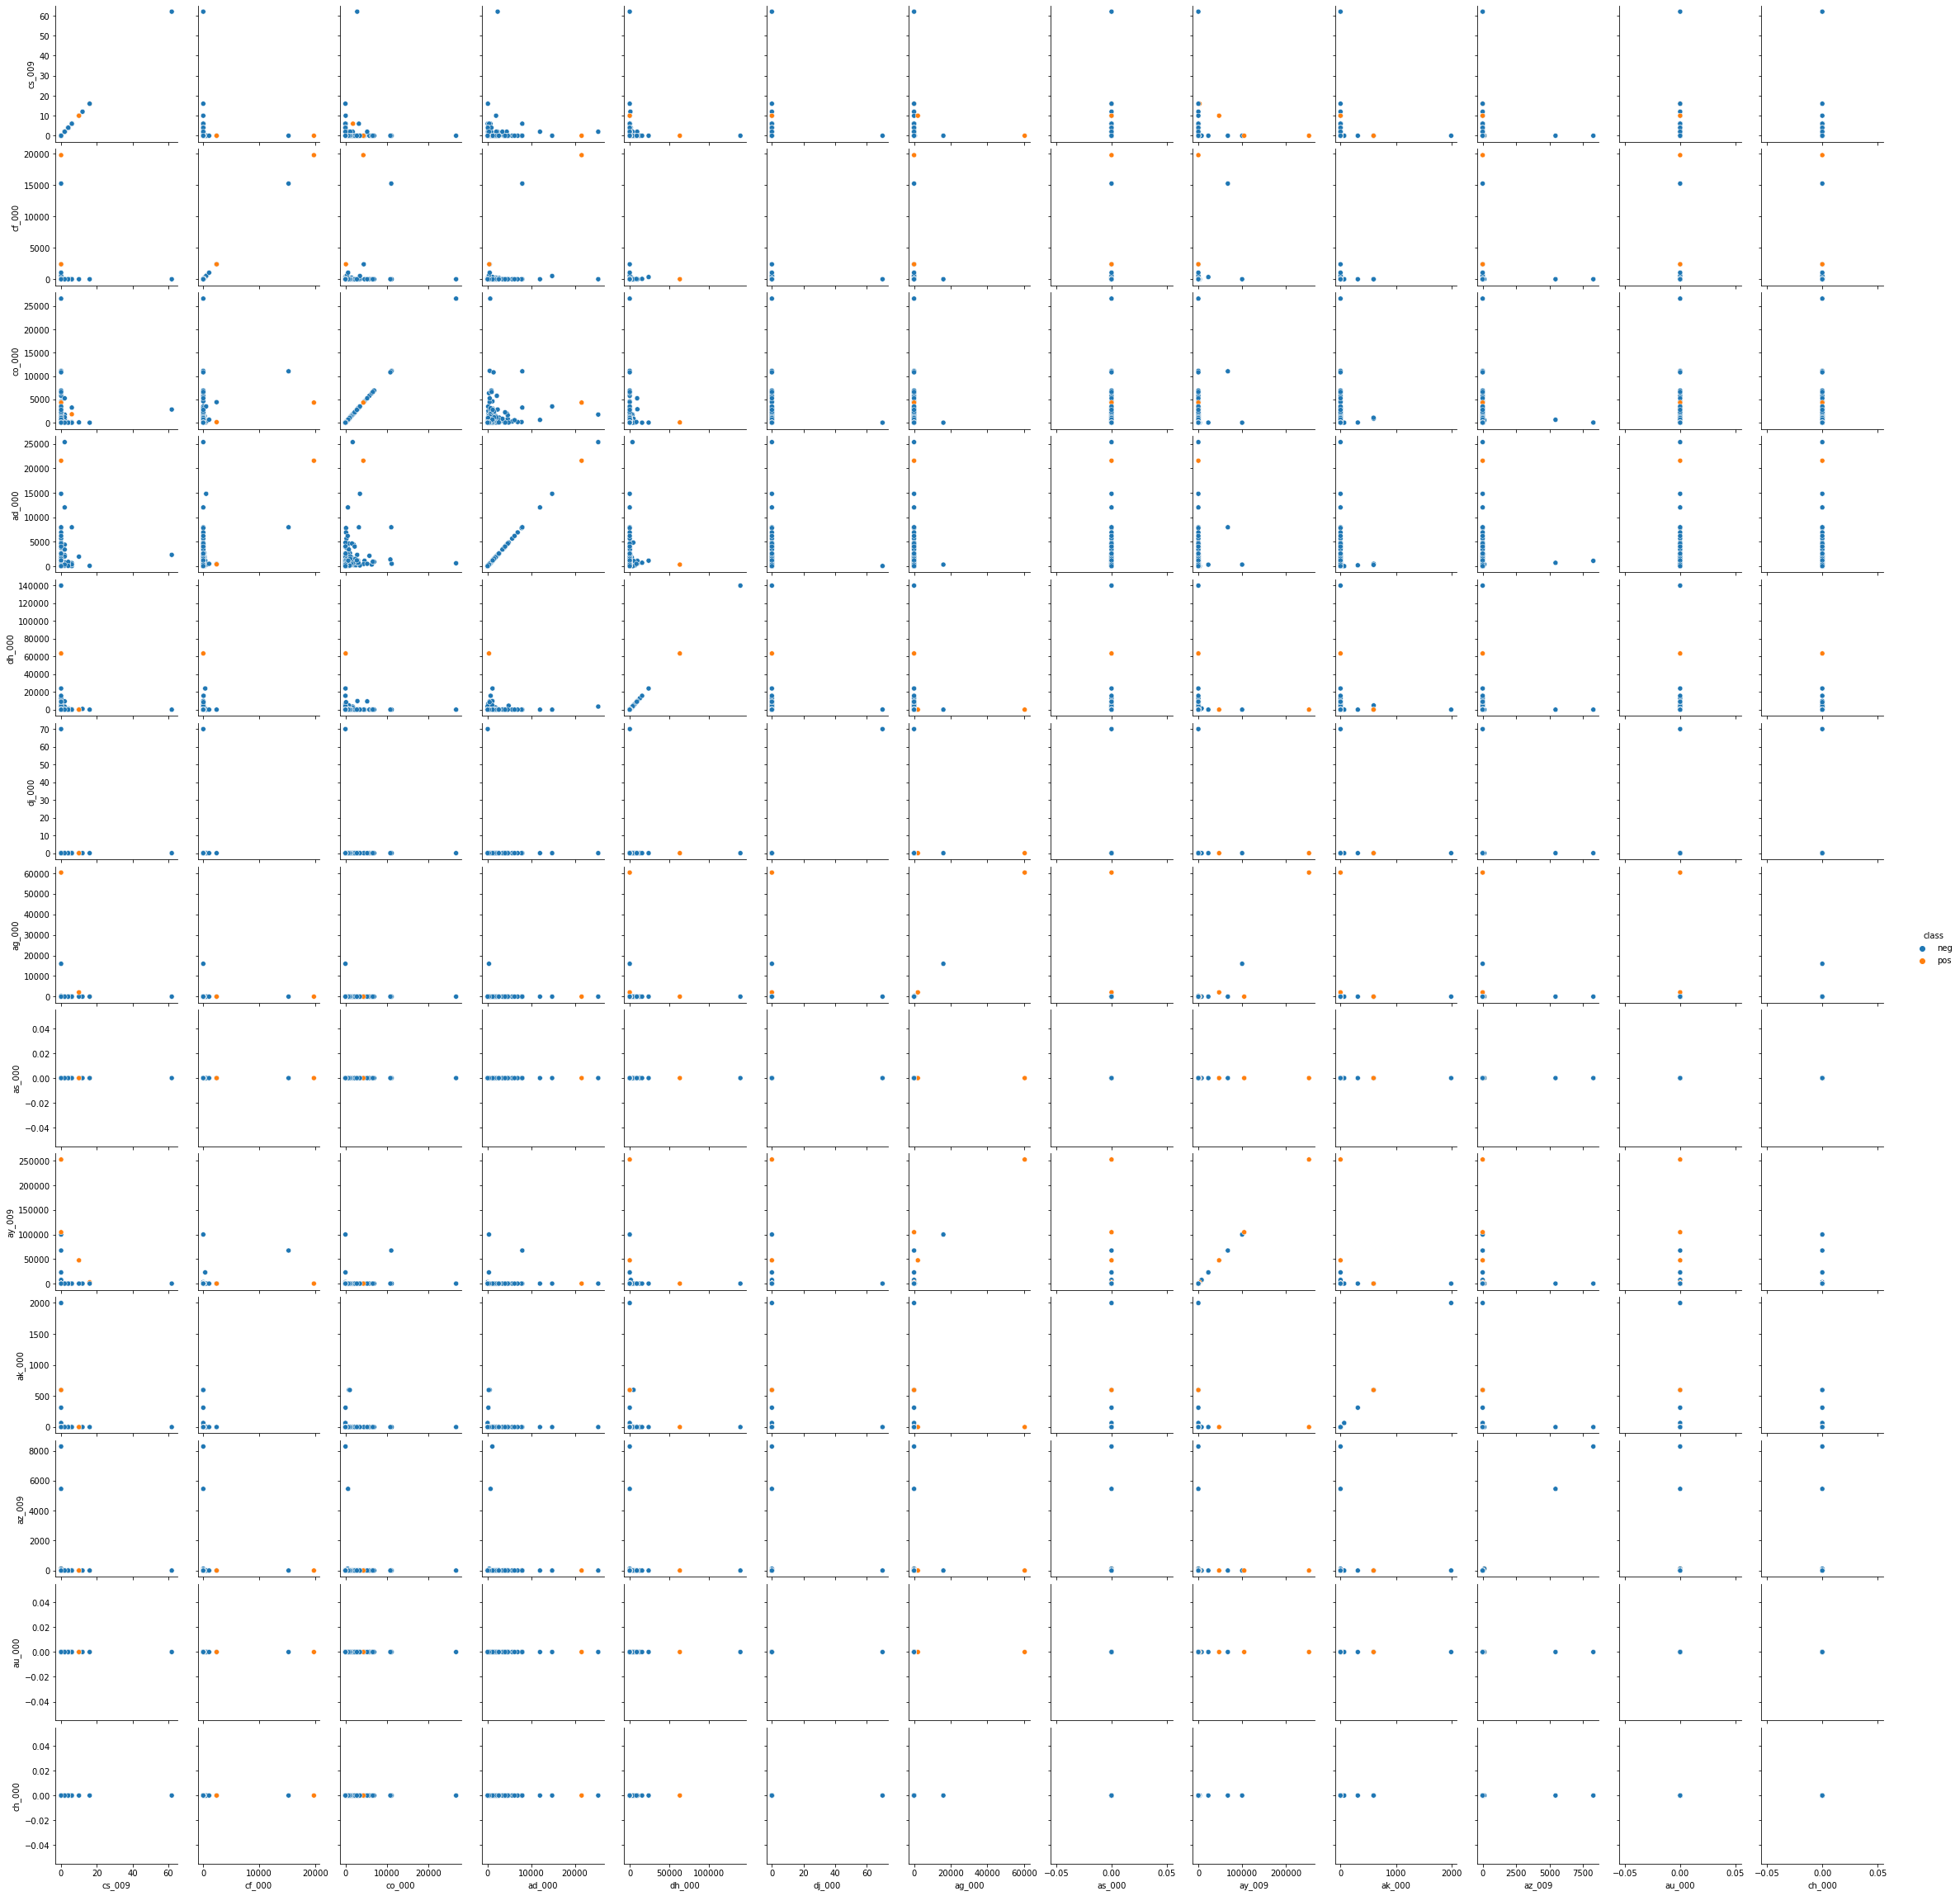

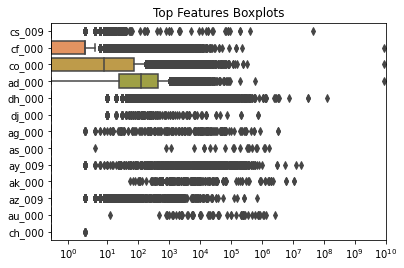

In [6]:
highest_cv = cv.sort_values(ascending=False).iloc[:int(np.floor(np.sqrt(170)))]

top = df[list(highest_cv.index) + ["class"]]

top_sample = top.sample(n=1000, random_state=42)
pairplots = sns.pairplot(top_sample, hue="class", diag_kind=None)
plt.show()

box = sns.boxplot(data=top.drop(columns="class"),orient="h")
box.set(xscale="symlog", xlim=(1e-5, 1e10))
plt.title("Top Features Boxplots")
plt.show()

We cannot draw conclusions about significant of those features, just by the scatter plots. Scatter plots show possible relationships and trends between features but they cannot determine statistical significance.

#### (v) Is this data set imbalanced?

In [7]:
count = df["class"].value_counts()

print(count)

neg    59000
pos     1000
Name: class, dtype: int64


This data set is imbalanced, because there are 1000 positive observations compared to 59,000 negative observations. Positive class is only 1.67% of the total observations.

### (c) Train a random forest

In [8]:
X_train = df.drop(columns="class")
y_train = df["class"]

X_test = test_df.drop(columns="class")
y_test = test_df["class"]

imputer = SimpleImputer(strategy="median")

X_train_imputed = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns, index=X_train.index)

imputer_test = SimpleImputer(strategy="median")
X_test_imputed = pd.DataFrame(imputer_test.fit_transform(X_test), columns=X_test.columns, index=X_test.index)

In [9]:
rf = RandomForestClassifier(n_estimators=100, oob_score=True, random_state=42)
rf.fit(X_train_imputed, y_train)

y_train_pred = rf.predict(X_train_imputed)
y_test_pred = rf.predict(X_test_imputed)

y_train_prob = rf.predict_proba(X_train_imputed)[:, 1]
y_test_prob = rf.predict_proba(X_test_imputed)[:, 1]

In [10]:
train_cm = confusion_matrix(y_train, y_train_pred)
test_cm = confusion_matrix(y_test, y_test_pred)

train_error = 1 - accuracy_score(y_train, y_train_pred)
test_error = 1 - accuracy_score(y_test, y_test_pred)

print("Train Confusion Matrix:")
print(train_cm)
print("Train Misclassification Error:", train_error)
print("Test Confusion Matrix:")
print(test_cm)
print("Test Misclassification Error:", test_error)

Train Confusion Matrix:
[[59000     0]
 [    1   999]]
Train Misclassification Error: 1.666666666666483e-05
Test Confusion Matrix:
[[15610    15]
 [  106   269]]
Test Misclassification Error: 0.0075625000000000275


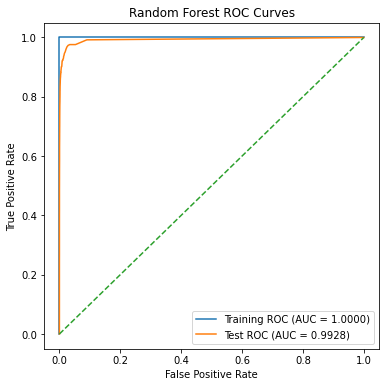

In [11]:
train_false_positive_rate, train_true_positive_rate, _ = roc_curve(y_train, y_train_prob, pos_label="pos")
test_false_positive_rate, test_true_positive_rate, _ = roc_curve(y_test, y_test_prob, pos_label="pos")

train_auc = roc_auc_score(y_train == "pos", y_train_prob)
test_auc = roc_auc_score(y_test == "pos", y_test_prob)

plt.figure(figsize=(6, 6))
plt.plot(train_false_positive_rate, train_true_positive_rate, label=f"Training ROC (AUC = {train_auc:.4f})")
plt.plot(test_false_positive_rate, test_true_positive_rate, label=f"Test ROC (AUC = {test_auc:.4f})")
plt.plot([0, 1], [0, 1], "--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curves")
plt.legend()
plt.show()

In [12]:
oob_error = 1 - rf.oob_score_

print("OOB Error:", oob_error)
print("Test Misclassification Error:", test_error)

OOB Error: 0.006166666666666654
Test Misclassification Error: 0.0075625000000000275


OOB error is 0.006166666666666654 and test misclassification error comes relatively close at 0.0075625000000000275. OOB error is lower than test misclassification error though, indicating that OOB error provides a reasonable esetimate of the test error.

### (d) Research class imbalance in random forest

Some ways to address class imbalance in random forests are oversampling the minority class, undersampling the majority class, and using class weights. I will use class_weight="balanced" in the Random Forest classifier, which automatically gives more weight to the minority class and less to the majority class based on how many observations there are per class. This helps the model pay more attention to the positive class, which has fewer observations.

In [13]:
rf_balanced = RandomForestClassifier(n_estimators=100,oob_score=True,random_state=42,class_weight="balanced")
rf_balanced.fit(X_train_imputed, y_train)

y_train_pred_balanced = rf_balanced.predict(X_train_imputed)
y_test_pred_balanced = rf_balanced.predict(X_test_imputed)

y_train_prob_balanced = rf_balanced.predict_proba(X_train_imputed)[:, 1]
y_test_prob_balanced = rf_balanced.predict_proba(X_test_imputed)[:, 1]

In [14]:
train_cm_balanced = confusion_matrix(y_train, y_train_pred_balanced)
test_cm_balanced = confusion_matrix(y_test, y_test_pred_balanced)

train_error_balanced = 1 - accuracy_score(y_train, y_train_pred_balanced)
test_error_balanced = 1 - accuracy_score(y_test, y_test_pred_balanced)

print("Train Confusion Matrix:")
print(train_cm_balanced)
print("Train Misclassification Error:", train_error_balanced)
print("Test Confusion Matrix:")
print(test_cm_balanced)
print("Test Misclassification Error:", test_error_balanced)

Train Confusion Matrix:
[[59000     0]
 [    1   999]]
Train Misclassification Error: 1.666666666666483e-05
Test Confusion Matrix:
[[15611    14]
 [  160   215]]
Test Misclassification Error: 0.010874999999999968


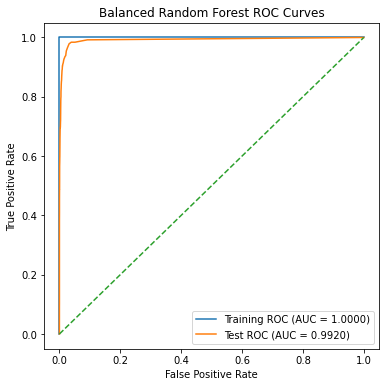

In [15]:
train_false_positive_rate_balanced, train_true_positive_rate_balanced, _ = roc_curve(y_train, y_train_prob_balanced, pos_label="pos")
test_false_positive_rate_balanced, test_true_positive_rate_balanced, _ = roc_curve(y_test, y_test_prob_balanced, pos_label="pos")

train_auc_balanced = roc_auc_score(y_train == "pos", y_train_prob_balanced)
test_auc_balanced = roc_auc_score(y_test == "pos", y_test_prob_balanced)

plt.figure(figsize=(6, 6))
plt.plot(train_false_positive_rate_balanced, train_true_positive_rate_balanced, label=f"Training ROC (AUC = {train_auc_balanced:.4f})")
plt.plot(test_false_positive_rate_balanced, test_true_positive_rate_balanced, label=f"Test ROC (AUC = {test_auc_balanced:.4f})")
plt.plot([0, 1], [0, 1], "--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Balanced Random Forest ROC Curves")
plt.legend()
plt.show()

In [16]:
oob_error_balanced = 1 - rf_balanced.oob_score_

print("Balanced RF OOB Error:", oob_error_balanced)
print("Balanced RF Test Misclassification Error:", test_error_balanced)

Balanced RF OOB Error: 0.008199999999999985
Balanced RF Test Misclassification Error: 0.010874999999999968


The OOB error is slightly lower than the test error for both models. The balanced random forest had a higher test error,1.0875% vs 0.7563%, and a lower test AUC (0.9920 vs 0.9928). It also correctly identified fewer positive cases (215 vs 269). Overall, using class weights did not improve the model's performance on the test set.

### (e) XGBoost and Model Trees

In [17]:
y_train_xgb = (y_train == "pos").astype(int)
y_test_xgb = (y_test == "pos").astype(int)

xgb = XGBClassifier(random_state=42,eval_metric="logloss")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

xgb_gridsearch = GridSearchCV(
    xgb,
    param_grid={"reg_alpha": [0, 0.01, 0.1, 1, 10]},
    cv=cv,
    scoring="accuracy"
)

xgb_gridsearch.fit(X_train_imputed, y_train_xgb)

chosen_alpha = xgb_gridsearch.best_params_["reg_alpha"]
best_cv_accuracy = xgb_gridsearch.best_score_
best_cv_error = 1 - best_cv_accuracy

print("Chosen alpha:", chosen_alpha)
print("CV Accuracy:", best_cv_accuracy)
print("CV Error:", best_cv_error)

Chosen alpha: 0
CV Accuracy: 0.9947999999999999
CV Error: 0.0052000000000000934


In [18]:
xgb = XGBClassifier(random_state=42,eval_metric="logloss",reg_alpha=chosen_alpha)
xgb.fit(X_train_imputed, y_train_xgb)

y_train_pred_xgb = xgb.predict(X_train_imputed)
y_test_pred_xgb = xgb.predict(X_test_imputed)

y_train_prob_xgb = xgb.predict_proba(X_train_imputed)[:, 1]
y_test_prob_xgb = xgb.predict_proba(X_test_imputed)[:, 1]

In [19]:
train_cm_xgb = confusion_matrix(y_train_xgb, y_train_pred_xgb)
test_cm_xgb = confusion_matrix(y_test_xgb, y_test_pred_xgb)

train_error_xgb = 1 - accuracy_score(y_train_xgb, y_train_pred_xgb)
test_error_xgb = 1 - accuracy_score(y_test_xgb, y_test_pred_xgb)

print("Train Confusion Matrix:")
print(train_cm_xgb)
print("Train Misclassification Error:", train_error_xgb)
print("Test Confusion Matrix:")
print(test_cm_xgb)
print("Test Misclassification Error:", test_error_xgb)

Train Confusion Matrix:
[[59000     0]
 [    1   999]]
Train Misclassification Error: 1.666666666666483e-05
Test Confusion Matrix:
[[15608    17]
 [   83   292]]
Test Misclassification Error: 0.006249999999999978


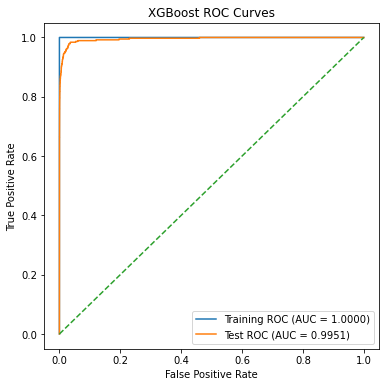

In [20]:
train_false_positive_rate_xgb, train_true_positive_rate_xgb, _ = roc_curve(y_train_xgb, y_train_prob_xgb)

test_false_positive_rate_xgb, test_true_positive_rate_xgb, _ = roc_curve(y_test_xgb, y_test_prob_xgb)

train_auc_xgb = roc_auc_score(y_train_xgb, y_train_prob_xgb)
test_auc_xgb = roc_auc_score(y_test_xgb, y_test_prob_xgb)

plt.figure(figsize=(6, 6))
plt.plot(train_false_positive_rate_xgb, train_true_positive_rate_xgb, label=f"Training ROC (AUC = {train_auc_xgb:.4f})")
plt.plot(test_false_positive_rate_xgb, test_true_positive_rate_xgb, label=f"Test ROC (AUC = {test_auc_xgb:.4f})")
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost ROC Curves")
plt.legend()
plt.show()

Using 5 fold stratified cross-validation to estimate the model's error, chosen alpha was 0 with CV accuracy of 99.48% and an estimated error of 0.52%. The test misclassification error was 0.625%, which is slightly higher than the CV error. Since the two error rates are close, the CV estimate was reasonably consistent with the model's performance on the test set.

### (f) Use SMOTE to pre-process your data

In [21]:
train_data = pd.concat([X_train_imputed, y_train_xgb.rename("class")], axis=1)

neg = train_data[train_data["class"] == 0].sample(n=6000, random_state=42)
pos = train_data[train_data["class"] == 1]

train_sample = pd.concat([neg, pos]).sample(frac=1, random_state=42)

X_train_sample = train_sample.drop(columns="class")
y_train_sample = train_sample["class"]

In [22]:
xgb_smote = ImbPipeline([
    ("smote", SMOTE(random_state=42)),
    ("xgb", XGBClassifier(random_state=42, eval_metric="logloss"))
])

cv_folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

xgb_gridsearch_smote = GridSearchCV(
    xgb_smote,
    param_grid={"xgb__reg_alpha": [0, 0.01, 0.1, 1, 10]},
    cv=cv_folds,
    scoring="accuracy"
)

xgb_gridsearch_smote.fit(X_train_sample, y_train_sample)

chosen_alpha_smote = xgb_gridsearch_smote.best_params_["xgb__reg_alpha"]
cv_accuracy_smote = xgb_gridsearch_smote.best_score_
cv_error_smote = 1 - cv_accuracy_smote

print("Chosen alpha:", chosen_alpha_smote)
print("CV Accuracy:", cv_accuracy_smote)
print("CV Error:", cv_error_smote)

Chosen alpha: 0
CV Accuracy: 0.9728571428571428
CV Error: 0.027142857142857246


In [23]:
xgb_smote_final = ImbPipeline([
    ("smote", SMOTE(random_state=42)),
    ("xgb", XGBClassifier(random_state=42, eval_metric="logloss", reg_alpha=chosen_alpha_smote))
])

xgb_smote_final.fit(X_train_sample, y_train_sample)

y_train_pred_smote = xgb_smote_final.predict(X_train_imputed)
y_test_pred_smote = xgb_smote_final.predict(X_test_imputed)

y_train_prob_smote = xgb_smote_final.predict_proba(X_train_imputed)[:, 1]
y_test_prob_smote = xgb_smote_final.predict_proba(X_test_imputed)[:, 1]

In [24]:
train_cm_smote = confusion_matrix(y_train_xgb, y_train_pred_smote)
test_cm_smote = confusion_matrix(y_test_xgb, y_test_pred_smote)

train_error_smote = 1 - accuracy_score(y_train_xgb, y_train_pred_smote)
test_error_smote = 1 - accuracy_score(y_test_xgb, y_test_pred_smote)

print("Train Confusion Matrix:")
print(train_cm_smote)
print("Train Misclassification Error:", train_error_smote)
print("Test Confusion Matrix:")
print(test_cm_smote)
print("Test Misclassification Error:", test_error_smote)

Train Confusion Matrix:
[[57968  1032]
 [    0  1000]]
Train Misclassification Error: 0.017199999999999993
Test Confusion Matrix:
[[15312   313]
 [   24   351]]
Test Misclassification Error: 0.021062499999999984


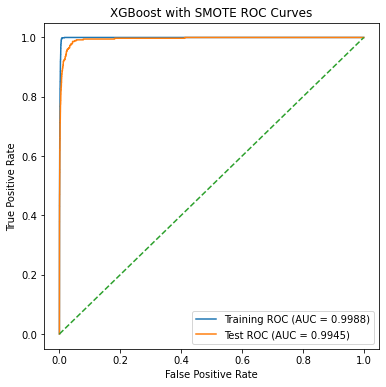

In [25]:
train_false_positive_rate_smote, train_true_positive_rate_smote, _ = roc_curve(y_train_xgb, y_train_prob_smote)

test_false_positive_rate_smote, test_true_positive_rate_smote, _ = roc_curve(y_test_xgb, y_test_prob_smote)

train_auc_smote = roc_auc_score(y_train_xgb, y_train_prob_smote)
test_auc_smote = roc_auc_score(y_test_xgb, y_test_prob_smote)

plt.figure(figsize=(6, 6))
plt.plot(train_false_positive_rate_smote, train_true_positive_rate_smote, label=f"Training ROC (AUC = {train_auc_smote:.4f})")
plt.plot(test_false_positive_rate_smote, test_true_positive_rate_smote, label=f"Test ROC (AUC = {test_auc_smote:.4f})")
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost with SMOTE ROC Curves")
plt.legend()
plt.show()

The model with SMOTE identified more positive cases and had fewer false negatives (24 vs 83). But it produced more false positives (313 vs 17), which increased the test misclassification error from 0.625% to 2.1063%. The test AUC was also slightly lower with SMOTE (0.9945 vs. 0.9951). SMOTE helped the model identify more positive cases, but it did not improve the overall test performance based on misclassification error and AUC.

The CV errors from the two models are not directly comparable because the model without SMOTE used the original training data, while the model with SMOTE used a downsampled training set. Both models were evaluated on the same original test set, so their test performance can be directly compared.

## 2. ISLR 6.6.3

a) Steadily decrease. As the value of s increases, the constratins become less restrictive. This allows coefficeints to take larger values, which gives the model increased flexibiltiy to fit the training data.So training RSS steadily decreases.

b) Decrease initially, and then eventually start increasing in a U shape. Initially, increasing s helps the model fit the data better, which lowers test RSS. Later when s value gets too large, the model may start overfitting the training data, causing the test RSS to increase.

c) Steadily increase. As s increases, the model becomes more flexible and more sensitive to the training data, which causes variance to increase.

d) Steadily decrease. As s increases, the model becomes more flexible and can thus capture patterns in the data better, which reduces the squared bias.

e) Remain constant. Irreducible error is not impacted by flexibility of the model, so as s increases, it'll remain constant.

## 3. ISLR 6.6.5

**a)** $$
min_{\beta_1,\beta_2}
\left\{
\sum_{i=1}^{2}(y_i-\beta_1x_{i1}-\beta_2x_{i2})^2
+\lambda(\beta_1^2+\beta_2^2)
\right\}
$$

and then since $x_{i1}=x_{i2}$ we can write:
$$
\min_{\beta_1,\beta_2}
\left[
(y_1-x_{11}(\beta_1+\beta_2))^2
+(y_2-x_{21}(\beta_1+\beta_2))^2
+\lambda(\beta_1^2+\beta_2^2)
\right]
$$

**b)** $$
(y_1-x_{11}(\beta_1+\beta_2))^2
+(y_2-x_{21}(\beta_1+\beta_2))^2
+\lambda(\beta_1^2+\beta_2^2)
$$

Taking partial derivative with respect to $\beta_1$:
$$
\frac{\partial f}{\partial \beta_1}
=
-2x_{11}(y_1-x_{11}(\beta_1+\beta_2))
-2x_{21}(y_2-x_{21}(\beta_1+\beta_2))
+2\lambda\beta_1=0
$$

Taking the partial derivative with respect to $\beta_2$:
$$
\frac{\partial f}{\partial \beta_2}
=
-2x_{11}(y_1-x_{11}(\beta_1+\beta_2))
-2x_{21}(y_2-x_{21}(\beta_1+\beta_2))
+2\lambda\beta_2=0
$$

Subtracting them equals:
$$
2\lambda\beta_1-2\lambda\beta_2=0
$$

so:
$$
\beta_1-\beta_2=0
$$

Thus:
$$
{\hat{\beta}_1=\hat{\beta}_2}
$$

**c)** $$
\min_{\beta_1,\beta_2}
\left[
\sum_{i=1}^{2}(y_i-\beta_1x_{i1}-\beta_2x_{i2})^2
+\lambda(|\beta_1|+|\beta_2|)
\right]
$$

For $n=2$:
$$
\min_{\beta_1,\beta_2}
\left[
(y_1-\beta_1x_{11}-\beta_2x_{12})^2
+(y_2-\beta_1x_{21}-\beta_2x_{22})^2
+\lambda(|\beta_1|+|\beta_2|)
\right]
$$

$x_{11}=x_{12}$ and $x_{21}=x_{22}$, so:
$$
{
\min_{\beta_1,\beta_2}
\left[
(y_1-x_{11}(\beta_1+\beta_2))^2
+(y_2-x_{21}(\beta_1+\beta_2))^2
+\lambda(|\beta_1|+|\beta_2|)
\right]
}
$$

**d)** Taking the partial derivative with respect to $\beta_1$ and setting it equal to zero:
$$
\begin{aligned}
&-2x_{11}[y_1-x_{11}(\beta_1+\beta_2)]\\
&-2x_{21}[y_2-x_{21}(\beta_1+\beta_2)]\\
&+\lambda(\pm 1)=0
\end{aligned}
$$

Taking the partial derivative with respect to $\beta_2$ and setting it equal to zero:
$$
\begin{aligned}
&-2x_{11}[y_1-x_{11}(\beta_1+\beta_2)]\\
&-2x_{21}[y_2-x_{21}(\beta_1+\beta_2)]\\
&+\lambda(\pm 1)=0
\end{aligned}
$$

Then:
$$
\lambda(\pm 1)-\lambda(\pm 1)=0
$$

The two coefficients can have different values while producing the same sum. Since the optimal sum is positive, different combinations of nonnegative coefficients can give the same residual sum of squares and lasso penalty. For ex, if the optimal sum is $S>0$, some combos coudl be:
$$
(\hat{\beta}_1,\hat{\beta}_2)
=
(S,0),\quad
(0,S),\quad
$$

These combinations have the same lasso penalty because:
$$
|\hat{\beta}_1|+|\hat{\beta}_2|
=\hat{\beta}_1+\hat{\beta}_2=S
$$
Therefore, there are multiple coefficient combinations that minimize the objective function, meaning the lasso estimates are not unique.

## 4. ISLR 8.4.5

**Majority vote approach:** Each model classifies the observation as Red if its estimated probability is greater than 0.5 (50%), and Green if it's less than 0.5. Here, 6 estimates are greater than 0.5, so those models predict Red. The other 4 estimates are less than 0.5, so those models predict Green

Since more than half of the models predict Red, the final classification using majority vote is **Red**. 

**Classify based on the average
probability:**

Average of the ten probabilities:
$$
\frac{0.1+0.15+0.2+0.2+0.55+0.6+0.6+0.65+0.7+0.75}{10}
=\frac{4.5}{10}=0.45
$$

Since the average probability of Red is less than 0.5, the final classification is **Green**

## 5. ISLR 9.7.3

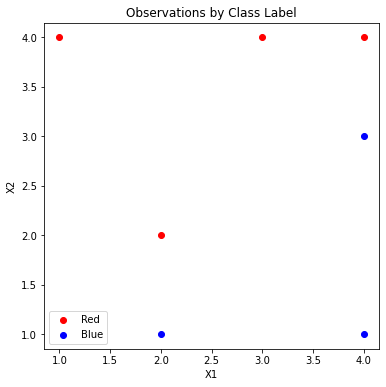

In [26]:
x1_red = [3,2,4,1]
x2_red = [4,2,4,4]

x1_blue = [2,4,4]
x2_blue = [1,3,1]

plt.figure(figsize=(6, 6))

plt.scatter(x1_red, x2_red, color="red", label="Red")
plt.scatter(x1_blue, x2_blue, color="blue", label="Blue")

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Observations by Class Label")
plt.legend()
plt.show()

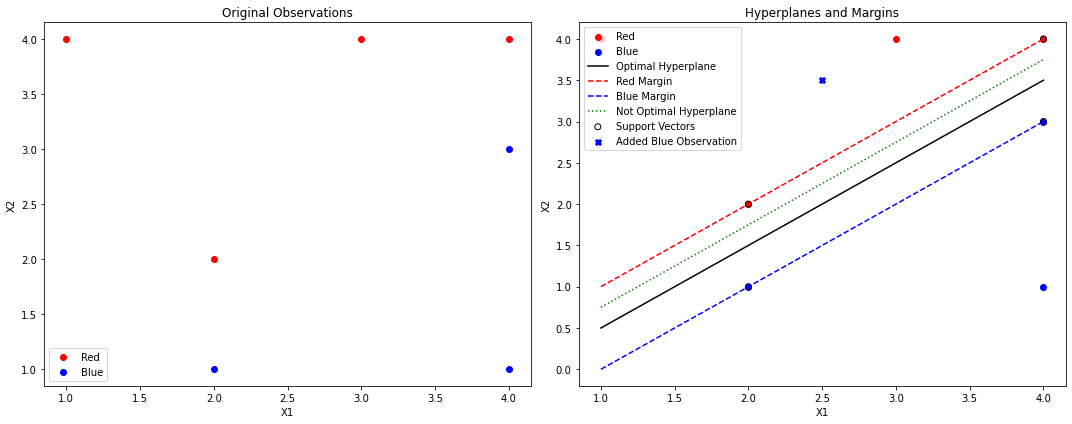

In [27]:
x = np.linspace(1, 4, 100)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].scatter(x1_red, x2_red, color="red", label="Red")
axes[0].scatter(x1_blue, x2_blue, color="blue", label="Blue")
axes[0].set_title("Original Observations")

axes[1].scatter(x1_red, x2_red, color="red", label="Red")
axes[1].scatter(x1_blue, x2_blue, color="blue", label="Blue")
axes[1].plot(x, x - 0.5, color="black", label="Optimal Hyperplane")
axes[1].plot(x, x, "r--", label="Red Margin")
axes[1].plot(x, x - 1, "b--", label="Blue Margin")
axes[1].plot(x, x - 0.25, color="green", linestyle=":", label="Not Optimal Hyperplane")
axes[1].scatter([2, 4, 2, 4], [2, 4, 1, 3], facecolors="none", edgecolors="black", label="Support Vectors")
axes[1].scatter(2.5, 3.5, color="blue", marker="X", label="Added Blue Observation")
axes[1].set_title("Hyperplanes and Margins")

for ax in axes:
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.legend()
plt.tight_layout()
plt.show()

**a)** First plot

**b)** Black line on second plot

**c)** **Red** if $\beta_0+\beta_1X_1+\beta_2X_2>0$,
**Blue** otherwise

Hyperplane:
$$
X_2=X_1-0.5
$$

$$
1-2X_1+2X_2=0
$$
Coefficients:
$$
{\beta_0=1,\quad \beta_1=-2,\quad \beta_2=2}
$$

**d)** Red and blue dashed lines on second plot

**e)** Support vectors are observations 2,3,5, and 6. They are circled in black on second plot

**f)** Slight movement of Observation 7 would not affect the maximal margin hyperplane because it's far away from the margin and is not a support vector. It will not affect the hyperplane as long as remains far away from the margin.

**g)** Dotted green line on second plot.
$$
{X_2=X_1-0.25}
$$
This still separates the Red and Blue observations, but it's not the optimal separating hyperplane because it's not centered between the two margin boundaries.

**h)** Added Blue observation at (2.5,3.5). This is in the region occupied by Red observations, so the two
classes are no longer separable by a hyperplane. It's the tilted plus sign looking symbol on second plot.